<a href="https://colab.research.google.com/github/tahta-id/Project-Google-Colab/blob/main/gtsrb_german_traffic_sign.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install kagglehub opencv-python numpy pandas tensorflow scikit-learn seaborn matplotlib

--- Mengunduh Dataset GTSRB via kagglehub ---
Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Path to dataset files: /kaggle/input/gtsrb-german-traffic-sign
File CSV Metadata ditemukan: /kaggle/input/gtsrb-german-traffic-sign/Train.csv
Total gambar valid yang siap diproses: 39209
Sampel citra rambu lalu lintas untuk Modul 1-3: /kaggle/input/gtsrb-german-traffic-sign/Train/20/00020_00000_00000.png



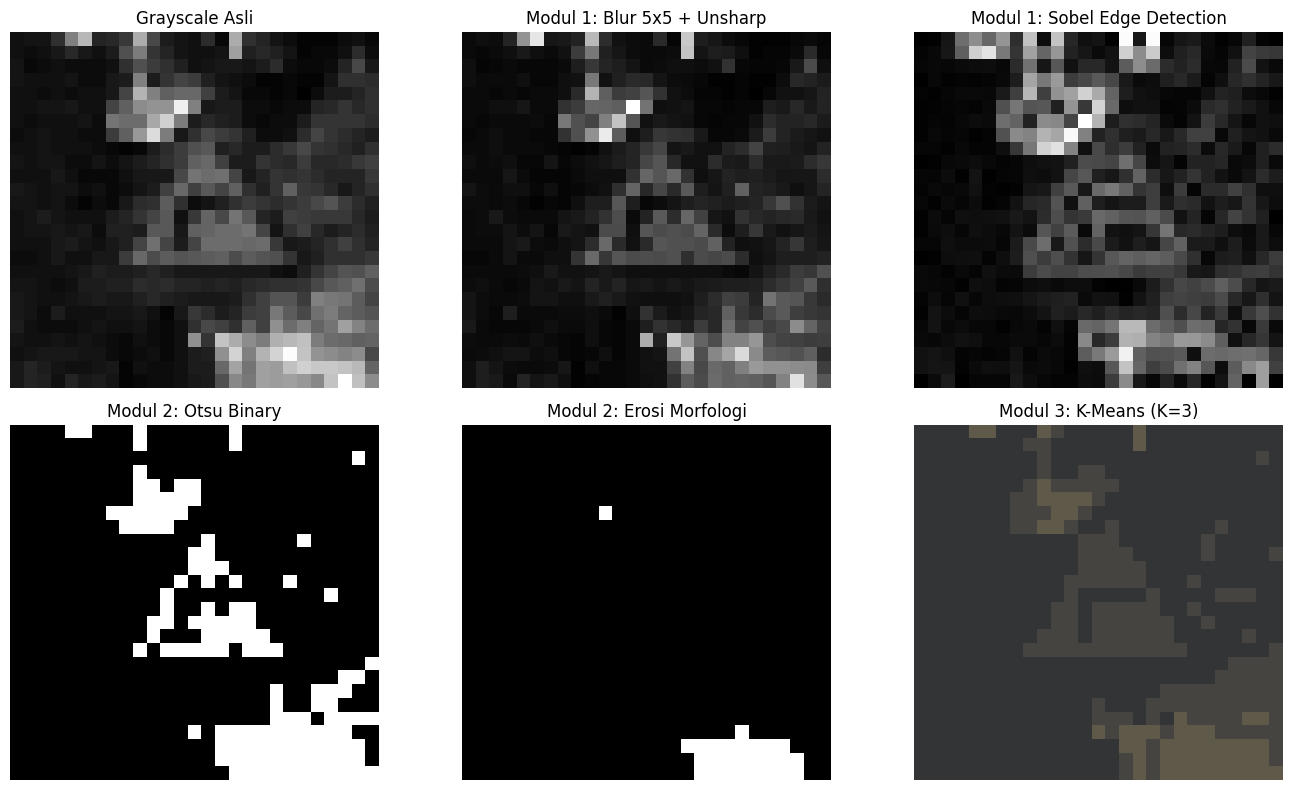


--- Modul 4: Membagi Dataset & Menyiapkan Data Generator ---
Found 8000 validated image filenames belonging to 43 classes.
Found 2000 validated image filenames belonging to 43 classes.
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Melatih Model EfficientNetB0 (Fine-Tuning) ---
Epoch 1/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 349s 1s/step - accuracy: 0.2371 - loss: 3.0379 - val_accuracy: 0.0490 - val_loss: 3.6515
Epoch 2/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 284s 1s/step - accuracy: 0.5304 - loss: 1.6328 - val_accuracy: 0.1750 - val_loss: 3.2827
Epoch 3/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 285s 1s/step - accuracy: 0.7189 - loss: 0.9482 - val_accuracy: 0.2290 - val_loss: 2.9940
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 219ms/step

================ CLASSIFICATION REPORT (SCIKIT-LEARN) ================
              precision    recall  f1-score   support

     Class_0       0.00      0.00      0.00        10
     Class_1       0.75      0.08      0.14       117
    Class_10       0.14      0.11      0.12       

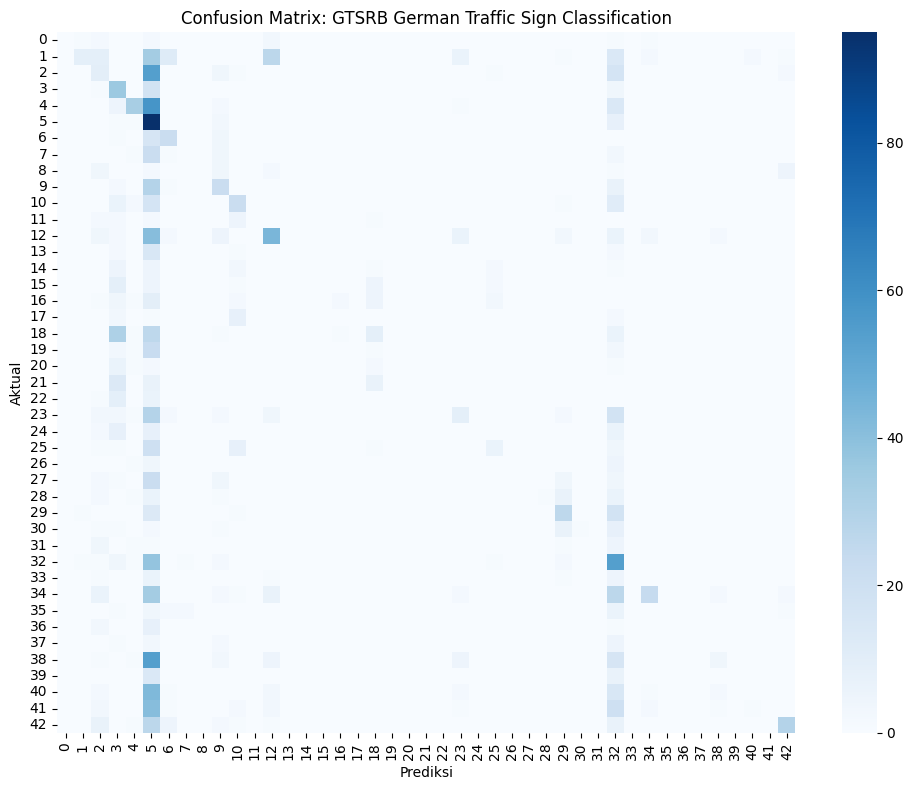

In [2]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import kagglehub

# =====================================================================
# 0. UNDUH DATASET GTSRB MENGGUNAKAN KAGGLEHUB & PERSIAPAN DATA
# =====================================================================
print("--- Mengunduh Dataset GTSRB via kagglehub ---")
path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print("Path to dataset files:", path)

# 1. Deteksi file CSV utama (Train.csv) dan direktori gambar
csv_files = glob.glob(os.path.join(path, "**", "Train.csv"), recursive=True)
if not csv_files:
    csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

if not csv_files:
    raise FileNotFoundError(f"File CSV tidak ditemukan di direktori: {path}")

train_csv_path = csv_files[0]
print(f"File CSV Metadata ditemukan: {train_csv_path}")

df = pd.read_csv(train_csv_path)

# 2. Cari semua gambar (.png / .jpg) di seluruh subfolder dataset
image_files = glob.glob(os.path.join(path, "**", "*.png"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True)

if not image_files:
    raise FileNotFoundError("Tidak ditemukan file gambar di dalam dataset GTSRB!")

# Buat dictionary pemetaan nama file ke path lengkapnya
image_map = {os.path.normpath(f): f for f in image_files}
basename_map = {os.path.basename(f): f for f in image_files}

# Tautkan path gambar ke DataFrame
# GTSRB Train.csv biasanya memiliki kolom 'Path' (misal: "Train/0/00000_00000.png")
if 'Path' in df.columns:
    df['file_path'] = df['Path'].apply(lambda x: image_map.get(os.path.normpath(os.path.join(path, x)),
                                                              basename_map.get(os.path.basename(x))))
else:
    df['file_path'] = df.iloc[:, 0].apply(lambda x: basename_map.get(os.path.basename(str(x))))

# Hapus data yang file gambarnya tidak terdeteksi
df = df.dropna(subset=['file_path']).reset_index(drop=True)

# Gunakan kolom ClassId sebagai string label target
label_col = 'ClassId' if 'ClassId' in df.columns else df.columns[-1]
df['class_str'] = df[label_col].astype(str)

print(f"Total gambar valid yang siap diproses: {len(df)}")

# Ambil 1 sampel gambar rambu untuk demonstrasi Modul 1-3
sample_img_path = df['file_path'].iloc[0]
print(f"Sampel citra rambu lalu lintas untuk Modul 1-3: {sample_img_path}\n")


# =====================================================================
# MODUL 1: Pemburaman Gauss 5x5, Unsharp Masking & Gradien Sobel
# =====================================================================
def modul_1_processing(image_path):
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise ValueError(f"Gagal memuat citra: {image_path}")

    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # 1. Pemburaman Gauss ukuran 5x5
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # 2. Pertajam dengan mengekstrak detail frekuensi spasial tinggi (Unsharp Masking)
    high_freq_detail = cv2.subtract(gray, blurred)
    sharpened = cv2.addWeighted(gray, 1.0, high_freq_detail, 1.5, 0)

    # 3. Perhitungan gradien tepi Sobel untuk identifikasi bentuk segitiga/segi delapan
    sobel_x = cv2.Sobel(sharpened, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(sharpened, cv2.CV_64F, 0, 1, ksize=3)

    sobel_mag = cv2.magnitude(sobel_x, sobel_y)
    sobel_uint8 = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

    return gray, sharpened, sobel_uint8


# =====================================================================
# MODUL 2: Binerisasi Ambang Otsu & Operasi Erosi Morfologi
# =====================================================================
def modul_2_processing(sharpened_img):
    # 1. Binerisasi area piktogram ikon rambu menggunakan ambang Otsu
    _, otsu_thresh = cv2.threshold(sharpened_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 2. Operasi erosi untuk mempertegas kelangsingan ikon putih dari piksel bocor
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    eroded_mask = cv2.erode(otsu_thresh, kernel, iterations=1)

    return otsu_thresh, eroded_mask


# =====================================================================
# MODUL 3: K-Means Color Segmentation (H,W,3 -> -1,3, K=3)
# =====================================================================
def modul_3_processing(image_path):
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # 1. Perombakan dimensi susunan piksel dari (H, W, 3) ke (-1, 3)
    pixel_values = img_rgb.reshape((-1, 3))
    pixel_values = np.float32(pixel_values)

    # 2. Penentuan pusat tiga warna optimal menggunakan K-Means (K=3)
    # Sentroid memisahkan: Pinggiran merah/biru, latar putih ikon, dan bayangan hitam
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    k = 3

    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    centers = np.uint8(centers)
    segmented_data = centers[labels.flatten()]
    segmented_image = segmented_data.reshape(img_rgb.shape)

    return segmented_image


# =====================================================================
# MODUL 4: Fine Tuning EfficientNetB0 (Batch 32) & Evaluasi Scikit-Learn
# =====================================================================
def modul_4_train_and_eval(df, img_size=(64, 64), batch_size=32, epochs=3):
    print("\n--- Modul 4: Membagi Dataset & Menyiapkan Data Generator ---")

    # Gunakan subset 10.000 sampel acak jika dataset terlalu besar untuk eksekusi cepat
    if len(df) > 10000:
        df_sample = df.sample(n=10000, random_state=42).reset_index(drop=True)
    else:
        df_sample = df

    train_df, val_df = train_test_split(df_sample, test_size=0.2, random_state=42, stratify=df_sample['class_str'])

    datagen = ImageDataGenerator(rescale=1./255)

    # Himpunan dataset kelas rambu jalan berukuran batch 32 gambar per putaran
    train_gen = datagen.flow_from_dataframe(
        dataframe=train_df,
        x_col='file_path',
        y_col='class_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=True
    )

    val_gen = datagen.flow_from_dataframe(
        dataframe=val_df,
        x_col='file_path',
        y_col='class_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=False
    )

    num_classes = len(train_df['class_str'].unique())

    # 1. Arsitektur EfficientNetB0
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(img_size[0], img_size[1], 3))

    # 2. Bekukan seluruh layer
    base_model.trainable = True

    # Matikan trainable 20 lapisan ujung terdalam EfficientNet saat proses fine tuning
    for layer in base_model.layers[-20:]:
        layer.trainable = False

    inputs = layers.Input(shape=(img_size[0], img_size[1], 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    print("\n--- Melatih Model EfficientNetB0 (Fine-Tuning) ---")
    model.fit(train_gen, validation_data=val_gen, epochs=epochs)

    # 3. Prediksi dan ukur presisi model via pustaka scikit-learn
    val_gen.reset()
    y_pred_probs = model.predict(val_gen)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = val_gen.classes

    # Mapping label
    labels_map = {v: k for k, v in val_gen.class_indices.items()}
    class_names = [f"Class_{labels_map[i]}" for i in range(num_classes)]

    print("\n================ CLASSIFICATION REPORT (SCIKIT-LEARN) ================")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    # Heatmap Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=False, cmap='Blues')
    plt.title('Confusion Matrix: GTSRB German Traffic Sign Classification')
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.tight_layout()
    plt.show()


# =====================================================================
# EKSEKUSI PIPELINE
# =====================================================================
if __name__ == "__main__":
    # Run Modul 1, 2, dan 3
    gray_img, sharpened_img, sobel_uint8 = modul_1_processing(sample_img_path)
    otsu_thresh, eroded_mask = modul_2_processing(sharpened_img)
    kmeans_segmented = modul_3_processing(sample_img_path)

    # Visualisasi Hasil Modul 1 - 3
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes[0, 0].imshow(gray_img, cmap='gray')
    axes[0, 0].set_title('Grayscale Asli')

    axes[0, 1].imshow(sharpened_img, cmap='gray')
    axes[0, 1].set_title('Modul 1: Blur 5x5 + Unsharp')

    axes[0, 2].imshow(sobel_uint8, cmap='gray')
    axes[0, 2].set_title('Modul 1: Sobel Edge Detection')

    axes[1, 0].imshow(otsu_thresh, cmap='gray')
    axes[1, 0].set_title('Modul 2: Otsu Binary')

    axes[1, 1].imshow(eroded_mask, cmap='gray')
    axes[1, 1].set_title('Modul 2: Erosi Morfologi')

    axes[1, 2].imshow(kmeans_segmented)
    axes[1, 2].set_title('Modul 3: K-Means (K=3)')

    for ax in axes.ravel():
        ax.axis('off')
    plt.tight_layout()
    plt.show()

    # Run Modul 4 (Training & Evaluasi Model)
    modul_4_train_and_eval(df, epochs=3)